In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dhrubangtalukdar/telco-customer-churn-data/synthetic_customer_churn_100k.csv


In [16]:
# import dataset
data=pd.read_csv("/kaggle/input/datasets/dhrubangtalukdar/telco-customer-churn-data/synthetic_customer_churn_100k.csv")
data

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No
...,...,...,...,...,...,...,...,...,...
99995,99996,31,Male,49,26.07,Month-to-month,Electronic check,1220.50,No
99996,99997,64,Female,44,123.22,Month-to-month,Mailed check,5384.38,No
99997,99998,48,Other,32,75.37,Month-to-month,Credit card,2372.33,Yes
99998,99999,42,Female,60,114.00,Month-to-month,Mailed check,6826.55,No


In [17]:
# copy the dataset
df=data.copy()
df

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No
...,...,...,...,...,...,...,...,...,...
99995,99996,31,Male,49,26.07,Month-to-month,Electronic check,1220.50,No
99996,99997,64,Female,44,123.22,Month-to-month,Mailed check,5384.38,No
99997,99998,48,Other,32,75.37,Month-to-month,Credit card,2372.33,Yes
99998,99999,42,Female,60,114.00,Month-to-month,Mailed check,6826.55,No


In [18]:
# check null value
df.isnull().sum()

CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

In [19]:
# check duplicate value
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Length: 100000, dtype: bool

In [20]:
# data types
df.dtypes

CustomerID          int64
Age                 int64
Gender             object
Tenure              int64
MonthlyCharges    float64
Contract           object
PaymentMethod      object
TotalCharges      float64
Churn              object
dtype: object

In [21]:
df.shape

(100000, 9)

In [22]:
# how much imbalanced the dataset
counts = df['Churn'].value_counts()
ratio = counts.max() / counts.min()
print(f"Imbalance Ratio: {ratio:.2f}:1")

Imbalance Ratio: 2.02:1


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, classification_report
from imblearn.over_sampling import SMOTE


# DATA PREPROCESSING


# Drop non-predictive identifier columns which are  present
df = df.drop(columns=['CustomerID', 'customer_id', 'id'], errors='ignore')

# Standardize target column name ('Churn')
target_col = 'Churn' if 'Churn' in df.columns else [c for c in df.columns if 'churn' in c.lower()][0]

# Convert string target ('Yes'/'No') to numeric binary (1/0)
if df[target_col].dtype == 'object':
    df[target_col] = df[target_col].map({'Yes': 1, 'No': 0})

# Separate features (X) and target label (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# One-Hot Encode categorical predictors into numeric columns
X = pd.get_dummies(X, drop_first=True)
X



,Age,Tenure,MonthlyCharges,TotalCharges,Gender_Male,Gender_Other,Contract_One year,Contract_Two year,PaymentMethod_Credit card,PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,56,68,147.58,10052.03,False,False,False,True,False,False,False
1,69,32,22.54,686.78,True,False,False,False,False,False,True
2,46,10,52.47,537.88,False,False,True,False,False,True,False
3,32,22,109.67,2390.04,True,False,False,False,False,False,True
4,60,54,130.98,7081.28,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...
99995,31,49,26.07,1220.50,True,False,False,False,False,True,False
99996,64,44,123.22,5384.38,False,False,False,False,False,False,True
99997,48,32,75.37,2372.33,False,True,False,False,True,False,False
99998,42,60,114.00,6826.55,False,False,False,False,False,False,True


In [24]:
#  STRATIFIED TRAIN-TEST SPLIT & SCALING

print("\n  Train-Test Split & Feature Scaling ")

# Stratified split preserves original 80:20 class ratio in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Original Training Class Distribution:\n{y_train.value_counts()}")

# Scale continuous features 
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)





  Train-Test Split & Feature Scaling 
Original Training Class Distribution:
Churn
0    53485
1    26515
Name: count, dtype: int64


In [25]:
X_train_scaled
X_test_scaled

,Age,Tenure,MonthlyCharges,TotalCharges,Gender_Male,Gender_Other,Contract_One year,Contract_Two year,PaymentMethod_Credit card,PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.153468,0.261386,-1.639710,-0.984500,-0.958006,4.919836,1.718020,-0.496208,-0.500625,1.365470,-0.581584
1,-0.771591,1.607795,-0.120065,0.969757,-0.958006,-0.203259,1.718020,-0.496208,1.997503,-0.732348,-0.581584
2,0.383444,0.597988,-0.760240,-0.193036,1.043835,-0.203259,1.718020,-0.496208,-0.500625,-0.732348,1.719441
3,-1.211605,0.213300,-0.209369,-0.001270,1.043835,-0.203259,-0.582065,-0.496208,-0.500625,-0.732348,-0.581584
4,-1.321608,-1.710143,1.239967,-1.194670,-0.958006,4.919836,1.718020,-0.496208,1.997503,-0.732348,-0.581584
...,...,...,...,...,...,...,...,...,...,...,...
19995,0.603451,-1.421626,-1.611834,-1.187353,-0.958006,-0.203259,-0.582065,-0.496208,-0.500625,-0.732348,-0.581584
19996,-0.826593,-1.373540,-0.783430,-1.092299,1.043835,-0.203259,-0.582065,2.015284,-0.500625,1.365470,-0.581584
19997,-0.661588,0.790332,0.687123,1.133418,1.043835,-0.203259,1.718020,-0.496208,-0.500625,-0.732348,1.719441
19998,0.273441,-0.507991,0.663686,-0.046612,1.043835,-0.203259,-0.582065,-0.496208,1.997503,-0.732348,-0.581584


Resampled Training Class Distribution:
Churn
0    53485
1    53485
Name: count, dtype: int64


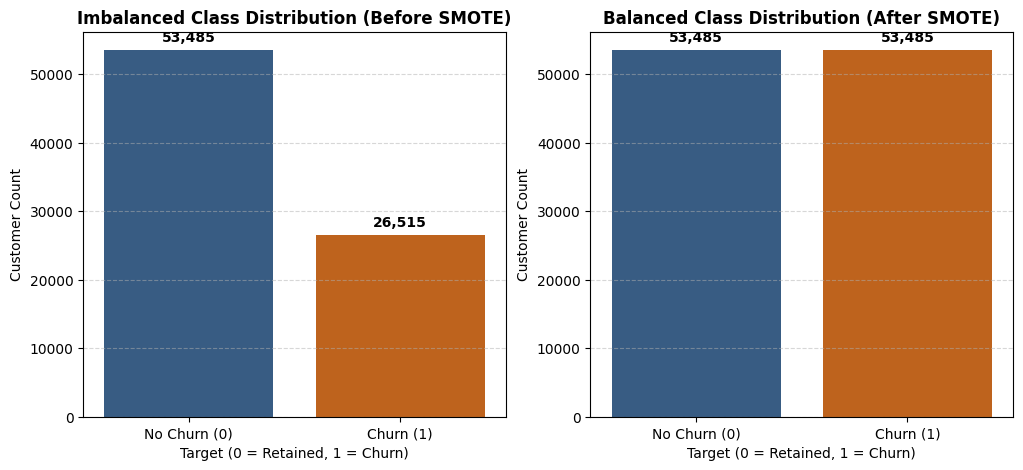

In [26]:
#  PREPROCESS IMBALANCED DATA USING SMOTE & VISUALIZE

# Fit SMOTE exclusively on training data to prevent test leakage
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f"Resampled Training Class Distribution:\n{pd.Series(y_train_res).value_counts()}")

# Visualizing Imbalanced vs. Balanced Class Distribution 
plt.figure(figsize=(12, 5))

# Plot :Original Imbalanced Class Distribution (Before SMOTE)
plt.subplot(1, 2, 1)
ax1 = sns.countplot(
    x=y_train, 
    hue=y_train, 
    palette=["#2b5c8f", "#d95f02"], 
    legend=False
)
plt.title("Imbalanced Class Distribution (Before SMOTE)", fontsize=12, fontweight='bold')
plt.xlabel("Target (0 = Retained, 1 = Churn)")
plt.ylabel("Customer Count")
plt.xticks([0, 1], ['No Churn (0)', 'Churn (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate counts on top of bars
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height()):,}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', fontsize=10, xytext=(0, 4), 
                 textcoords='offset points', fontweight='bold')

#  Balanced Class Distribution 
plt.subplot(1, 2, 2)
ax2 = sns.countplot(
    x=y_train_res, 
    hue=y_train_res, 
    palette=["#2b5c8f", "#d95f02"], 
    legend=False
)
plt.title("Balanced Class Distribution (After SMOTE)", fontsize=12, fontweight='bold')
plt.xlabel("Target (0 = Retained, 1 = Churn)")
plt.ylabel("Customer Count")
plt.xticks([0, 1], ['No Churn (0)', 'Churn (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate counts on top of bars
for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height()):,}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', fontsize=10, xytext=(0, 4), 
                 textcoords='offset points', fontweight='bold')

In [28]:
#  MODEL TRAINING (LOGISTIC REGRESSION & DECISION TREE)


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42)
}

results = []

for name, model in models.items():
    print(f"Training {name}")
    model.fit(X_train_res, y_train_res)
    
    # Predict on the untouched imbalanced test set
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Calculate key metrics
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
results.append({
        "Model": name,
        "Recall": round(rec, 4),
        "Precision": round(prec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })


Training Logistic Regression
Training Decision Tree


        Model  Recall  Precision  F1-Score  ROC-AUC
Decision Tree  0.5945     0.6385    0.6157   0.7991


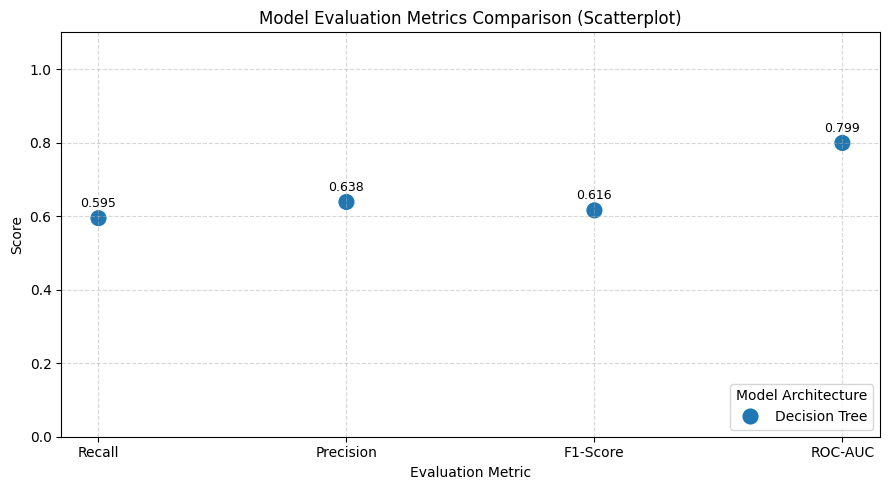

In [29]:
# MODEL EVALUATION & SCATTERPLOT COMPARISON


results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
print(results_df.to_string(index=False))

# Reshape evaluation results for scatterplot visual comparison
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=results_melted, 
    x="Metric", 
    y="Score", 
    hue="Model", 
    style="Model", 
    s=160
)
# Annotate exact score next to each data point on the scatterplot
for idx, row in results_melted.iterrows():
    plt.annotate(
        f"{row['Score']:.3f}",
        (row['Metric'], row['Score']),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9
    )

plt.title("Model Evaluation Metrics Comparison (Scatterplot)", fontsize=12)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Model Architecture", loc="lower right")
plt.tight_layout()
plt.show()